# Presentación

1. Nome da persoa que realiza a resolución do traballo (non o nome de quen propuxo o
traballo).

Marcelo Fort Muñoz

2. Código para definir a función, incluidos os parámetros, e crear a gráfica no intervalo de
traballo. O intervalo non poderá cambiar ao longo do traballo e só pode conter unha,
como moito dúas, raíces (máximo 10 liñas).

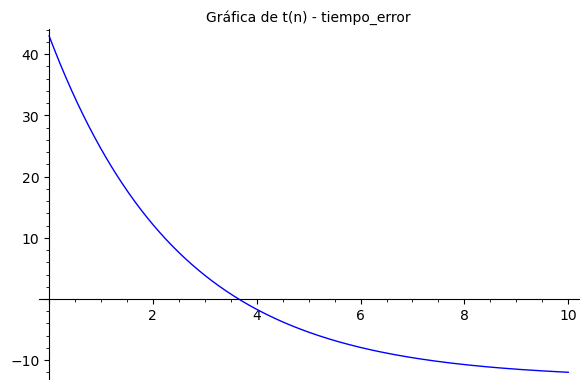

In [1]:
var('t')
a = 0
b = 10
Ta = 24
T0 = 80
xtol = 1e-3
temperatura_cuerpo_humano = 37
T(t) = Ta + (T0 - Ta) * e^(-0.4 * t)
TR(n) = T(n) - temperatura_cuerpo_humano
plot(TR, a, b, title = "Gráfica de t(n) - tiempo_error")

# Dicotomía

3. Código para calcular da raíz por dicotomía que só devolva a aproximación da raíz e o número de iteracións \(máximo 1 liña\).



In [14]:
dicotomia(TR,a,b,xtol)[0:2]

(3.65051269531250, 14)

4. Código para crear a gráfica dos iterantes de dicotomía e os intervalos encaixados no
intervalo de traballo (máximo 2 liñas).

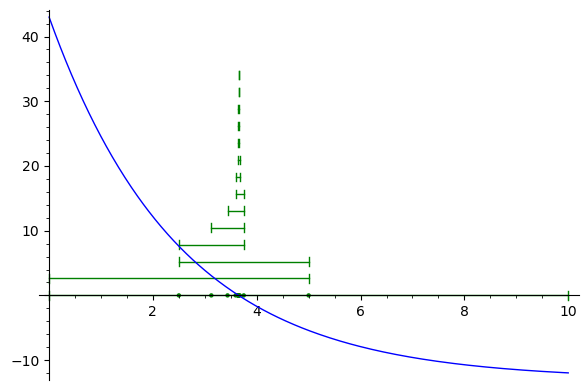

In [15]:
_,_,v,I = dicotomia(TR,a,b,xtol)
debuxa_dicotomia(TR,a,b,v,I)

5. Código para calcular o número máximo de iterantes (máximo 2 liñas).

In [16]:
kmax = lambda a, b, xtol: ceil(log( (b-a)/xtol, 2))
kmax(a, b, xtol)

14

6. Texto xustificando se o número de iteracións na práctica é coherente co número
máximo de iterantes (máximo 1 liña).

Sí, é coherente o valor obtido (14) ó estar no intervalo entre o 1 e o  máximo (14). Neste caso coincide que é o máximo.

# Newton

7. Código para calcular da raíz por Newton que só devolva a aproximación da raíz e o
número de iteracións (máximo 1 liña).

In [17]:
newton(TR,derivative(TR,n),a,xtol)[0:2]

(3.65100580451181, 6)

8. Código para crear a gráfica dos iterantes de Newton e as tanxente do método (máximo
2 liñas).

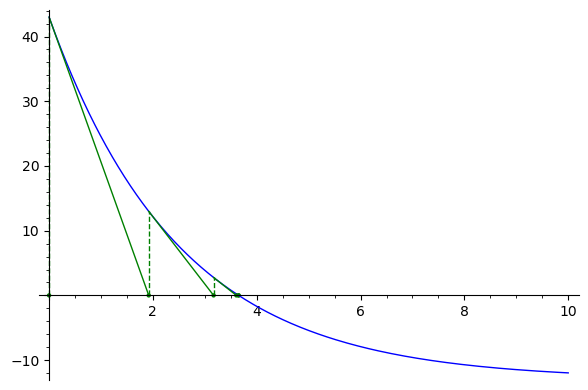

In [18]:
_, _, v = newton(TR,derivative(TR,n),a,xtol)
debuxa_newton(TR,a,b,v)

9. Código para crear a gráfica das constantes de converxencia, (máximo 1 liña).

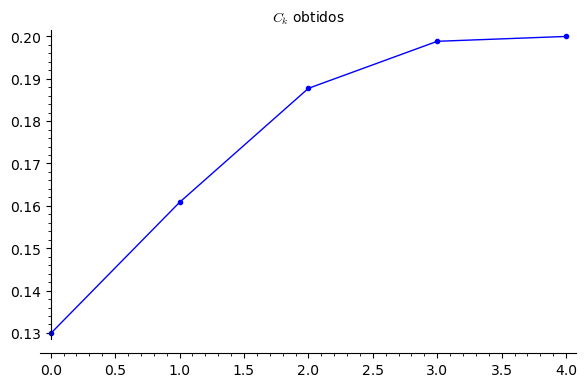

In [19]:
coef_newton(TR, a, b, v)

10. Texto xustificando se se dá a converxencia cuadrática neste caso (máximo 1 liña)

Dáse converxencia cuadrática, posto que os valores converxen aproximadamente ós 0.20 segundos a medida que medra o indíce dos iterantes calculados. Hai que ter en conta que puxen un kmax de 1e-3 xa que ó falar de segundos para a toma dun té non preciso máis precisión ó ser esta máis que suficiente.

In [8]:
def dicotomia(f, a, b, xtol=1e-12, rtol=1e-14):
    """DICOTOMIA Calculo de raices por dicotomia."""
    r = a
    k = 0
    v = []
    I = []
    # comprobacions previas
    if abs(f(a)).n() < rtol:
        r = a.n(); return r,k,v,I
    elif abs(f(b)).n() < rtol:
        r = b.n(); return r,k,v,I
    elif (f(a)*f(b)).n() > 0:
        raise RuntimeError('Extremos de igual signo.')
    # calculo iterativo
    while abs(b - a) > xtol:
        r = (a + b).n() / 2
        k = k + 1
        v.append(r)
        I.append((a,b))
        if abs(f(r)).n() < rtol:
            return r,k,v,I
        elif (f(a)*f(r)).n() < 0:
            b = r
        else:
            a = r
    return r,k,v,I

In [9]:
def debuxa_dicotomia(f, a, b, v, I):
    """DEBUXA_DICOTOMIA Visualiza intervalos de dicotomía."""
    p = plot(f, a, b) + point(zip(v,[0]*len(v)), color='green')
    h = (p.ymax() - p.ymin())/(1.5*len(v))
    show(sum(line([(a,h*i), (b,h*i)], color='green') + \
    line([(a,h*i-h/4),(a,h*i+h/4)], color='green') + \
    line([(b,h*i-h/4),(b,h*i+h/4)], color='green') \
    for i, (a,b) in enumerate(I)) + p, xmin=a, xmax=b)

In [10]:
def newton(f, df, x0, xtol=1e-12, rtol=1e-14, M=100, errorM=True):
    """NEWTON Calculo de raices por Newton."""
    v = [x0.n()]
    for k in range(M):
        dfx = df(v[k]).n()
        if abs(dfx) < rtol:
            raise RuntimeError('Derivada nula.')
        r = (v[k] - f(v[k]) / dfx).n()
        v.append(r)
        # test de parada
        if abs(r-v[k]) < xtol or abs(f(r)).n() < rtol:
            return r, len(v), v
    if errorM: raise RuntimeError('Excedido numero maximo de iteracions')
    return r, len(v), v

In [11]:
def debuxa_newton(f, a, b, v):
    """DEBUXA_NEWTON    Visualiza tanxentes do metodo de Newton."""
    show(plot(f, a, b) + point(zip(v,[0]*len(v)), color='green') + \
    sum(line([(v[i],0),(v[i],f(v[i]))], color='green', linestyle='--') for i in range(len(v))) + \
    sum(line([(v[i-1],f(v[i-1])), (v[i],0)], color='green') for i in range(1,len(v))), xmin=a, xmax=b)


In [12]:
def coef_newton(f, a, b, v):
    """COEF_NEWTON    Calcula os coeficientes de converxencia de Newton."""
    alpha = find_root(f, a, b, xtol=9.e-16, rtol=9.e-16) #aproximamos "ao máximo" a raíz
    pts = []
    for k in range(len(v)-1):
        if (alpha - v[k])^2 > RDF.epsilon():
            pts.append( (k, abs(alpha - v[k+1]) / (alpha - v[k])^2 ) )
    return line(pts, marker = '.', title='$C_k$ obtidos')